**Scope.** This notebook tests the patterns from our exploratory analysis and points out what in the data could be producing them. Income and acres burned are related across counties, so it looks at them together: which of the two is associated with FAIR Plan policy growth from 2022 to 2024, and whether that still holds without the counties that had very few policies in 2022 or no acres burned. The one-pair-at-a-time tests are in Nigel's `Statistical Analysis Code Scripts.R` instead: income vs. yearly policy growth (by year, with outlier checks), acres burned vs. growth, and growth by income group. His tables are `Statistical_Results.csv`, `Sensitivity_Analysis.csv` and `Income_Group_Growth_Summary.csv` in `data/processed/`.

Exposure per policy is not covered here. Nigel's income vs. exposure per policy results (2022–2024, with outlier checks) are in `Statistical_Results.csv` and `Sensitivity_Analysis.csv`.

## 1. Set up

### 1.1 Import packages

In [1]:
# 1.1 Import packages
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
import statsmodels.formula.api as smf
from scipy import stats

### 1.2 Set project folder paths

In [2]:
# 1.2 Set project folder paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / 'data' / 'raw'
processed_fldr = root_fldr / 'data' / 'processed'

## 2. Load and inspect

### 2.1 Load county table

In [3]:
# 2.1 Load the county table
county_table = pd.read_csv(
    processed_fldr/'County_Income_CFP_Fire_2022_2024.csv',
    )

### 2.2 Inspect county table

In [4]:
# 2.2 Number of rows and columns
county_table.shape

(58, 8)

In [5]:
# 2.3 Missing values in each column
county_table.isna().sum()

county                0
policies_2022         0
policies_2023         0
policies_2024         0
policy_growth_pct     0
Median_income         0
acres_burned_total    0
income_group          0
dtype: int64

In [6]:
# 2.4 Count counties with no acres burned
no_fire_mask = county_table["acres_burned_total"] == 0

no_fire_mask.sum()

np.int64(5)

In [7]:
# 2.5 List the 10 counties with the fewest FAIR Plan policies in 2022
(
    county_table
    [['county', 'policies_2022', 'policies_2024', 'policy_growth_pct']]
    .sort_values('policies_2022')
    .head(10)
)

,county,policies_2022,policies_2024,policy_growth_pct
50,Sutter,20.0,51.0,155.000000
10,Glenn,23.0,49.0,113.043478
5,Colusa,28.0,48.0,71.428571
15,Kings,46.0,117.0,154.347826
24,Modoc,52.0,195.0,275.000000
13,Inyo,55.0,188.0,241.818182
23,Merced,57.0,200.0,250.877193
56,Yolo,62.0,195.0,214.516129
49,Stanislaus,107.0,417.0,289.719626
34,San Benito,112.0,224.0,100.000000


### 2.6 Add columns for the models

In [8]:
# 2.6 Add income in $10k, log acres burned, and a small-base flag
county_table = (
    county_table
    .assign(
        income_10k = lambda df: df['Median_income']/10000,
        log_acres  = lambda df: np.log(df['acres_burned_total']+1),
        small_base = lambda df: df['county'].isin(['Sutter','Glenn','Colusa','Kings']),
    )
)


In [9]:
# 2.7 Check the new columns
print(county_table.shape)                
print(county_table['small_base'].sum())  
print(county_table['log_acres'].min())   

(58, 11)
4
0.0


## 3. Shape of the data (histograms)

### 3.1 Policy growth

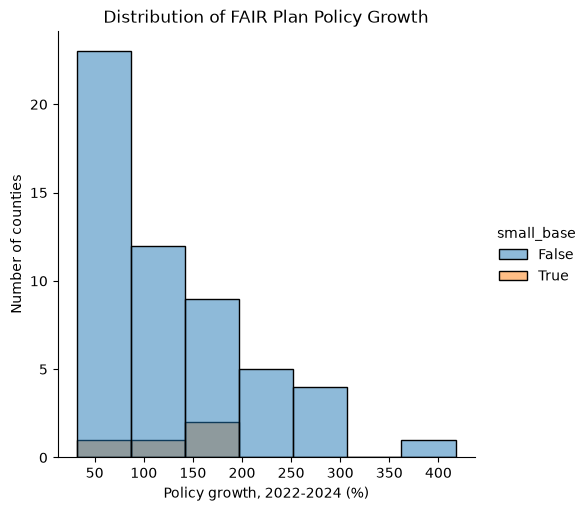

In [10]:
# 3.1 Distribution of policy growth, flagged counties in a second colour
g = sns.displot(
    data=county_table,
    x='policy_growth_pct',
    hue='small_base',
).set(
    title  = 'Distribution of FAIR Plan Policy Growth',
    xlabel = 'Policy growth, 2022-2024 (%)',
    ylabel = 'Number of counties',
);


### 3.2 Raw acres burned

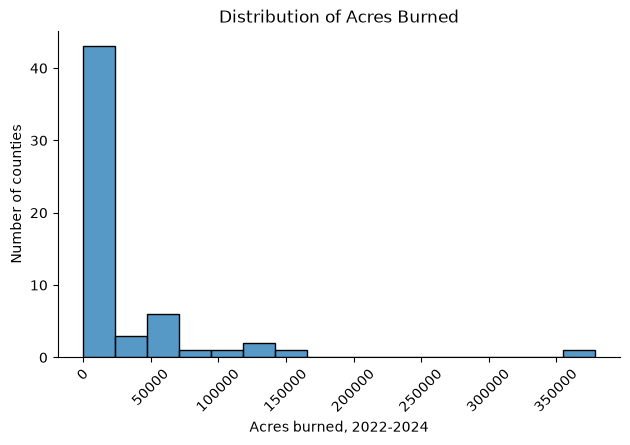

In [11]:
# 3.2 Distribution of acres burned
g = sns.displot(
    data=county_table,
    x='acres_burned_total',
    height=4,
    aspect=1.6,
).set(
    title  = 'Distribution of Acres Burned',
    xlabel = 'Acres burned, 2022-2024',
    ylabel = 'Number of counties',
);
g.tick_params(axis='x', rotation=45);

### 3.3 Log acres

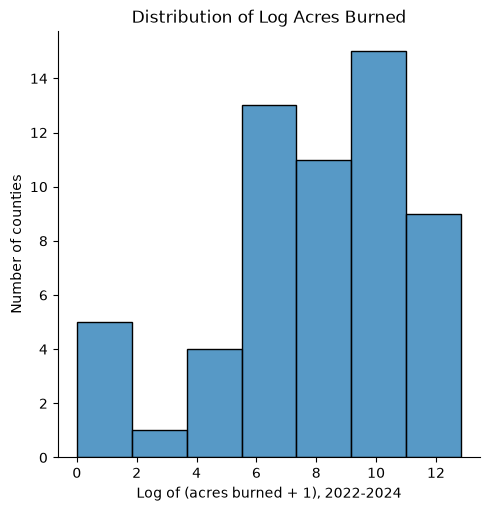

In [12]:
# 3.3 Distribution of log acres burned
g = sns.displot(
    data=county_table,
    x='log_acres',
).set(
    title  = 'Distribution of Log Acres Burned',
    xlabel = 'Log of (acres burned + 1), 2022-2024',
    ylabel = 'Number of counties',
);


## 4. Are income and acres burned related?

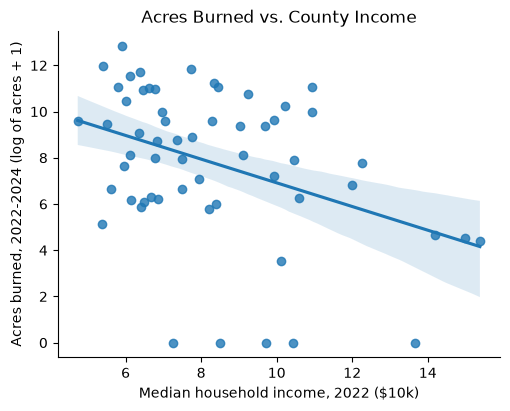

In [13]:
# 4.1 Income vs acres burned with a fitted line
g = sns.lmplot(
    data=county_table,
    x='income_10k',
    y='log_acres',
    height=4,
    aspect=1.3,
).set(
    title  = 'Acres Burned vs. County Income',
    xlabel = 'Median household income, 2022 ($10k)',
    ylabel = 'Acres burned, 2022-2024 (log of acres + 1)',
);


In [14]:
# 4.2 Correlation between income and acres burned
stats.pearsonr(county_table['income_10k'], county_table['log_acres'])


PearsonRResult(statistic=np.float64(-0.3915810937537153), pvalue=np.float64(0.00236841502796867))

Median income and log acres burned were negatively correlated (r = −0.39, p = 0.002), so higher-income counties tended to burn less between 2022 and 2024, and a link between policy growth and one of them could partly reflect the other; sections 5 and 6 look at each alone and then both together. In the plot the five zero-acre counties sit at middle to high incomes, so part of this correlation may come from them (not rechecked without them).


## 5. Each one alone vs. policy growth

### 5.1 Income alone

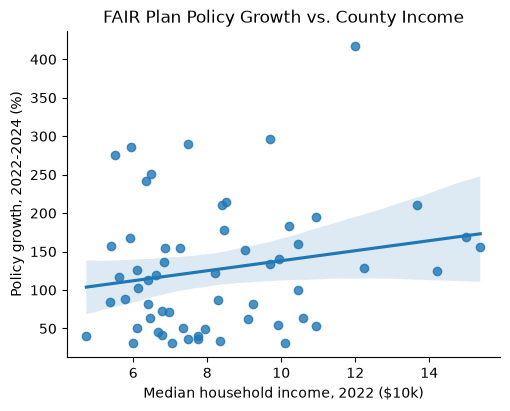

In [15]:
# 5.1 Income vs policy growth with a fitted line
g = sns.lmplot(
    data=county_table,
    x='income_10k',
    y='policy_growth_pct',
    height=4,
    aspect=1.3,
).set(
    title  = 'FAIR Plan Policy Growth vs. County Income',
    xlabel = 'Median household income, 2022 ($10k)',
    ylabel = 'Policy growth, 2022-2024 (%)',
);

In [16]:
# 5.2 Fit a straight line: policy growth explained by income
m_income = smf.ols("policy_growth_pct ~ income_10k", data=county_table).fit()


In [17]:
# 5.3 Show the model results
m_income.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.038
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     2.223
Date:                Mon, 16 Nov 2026   Prob (F-statistic):              0.142
Time:                        21:14:47   Log-Likelihood:                -337.13
No. Observations:                  58   AIC:                             678.3
Df Residuals:                      56   BIC:                             682.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     72.9931     37.809      1.931      0.059      -2.748     148.734
income_10k     6.5108      4.367      1.491      0.142      -2.237      15.258
==============================================================================
Omnibus:                       13.228   Durbin-Watson:                   1.772
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               13.988
Skew:                           1.113   Prob(JB):                     0.000917
Kurtosis:                       3.914   Cond. No.                         30.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

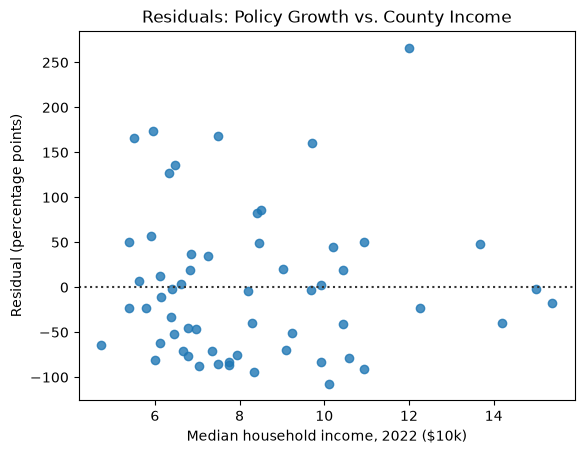

In [18]:
# 5.4 Residuals: distance of each county from the fitted line
sns.residplot(
    data=county_table,
    x='income_10k',
    y='policy_growth_pct',
).set(
    title  = 'Residuals: Policy Growth vs. County Income',
    xlabel = 'Median household income, 2022 ($10k)',
    ylabel = 'Residual (percentage points)',
);


Policy growth rose by about 6.5 percentage points per $10,000 of median income, but the slope was not distinguishable from zero (p = 0.14, R² = 0.04). Nigel's tests mostly point the same way: no link with 2022–2024 growth in either of his tests, no difference by income group (Kruskal-Wallis p = 0.403) and none with 2023 growth (p = 0.97); his 2024 test was borderline with all 58 counties (p = 0.048) but not without Contra Costa (p = 0.145).


### 5.5 Acres burned alone

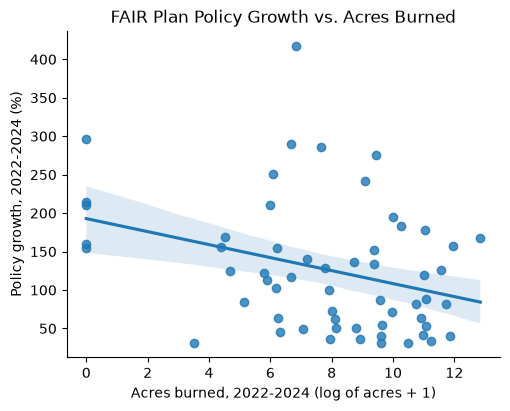

In [19]:
# 5.5 Acres burned vs policy growth with a fitted line
g = sns.lmplot(
    data=county_table,
    x='log_acres',
    y='policy_growth_pct',
    height=4,
    aspect=1.3,
).set(
    title  = 'FAIR Plan Policy Growth vs. Acres Burned',
    xlabel = 'Acres burned, 2022-2024 (log of acres + 1)',
    ylabel = 'Policy growth, 2022-2024 (%)',
);


In [20]:
# 5.6 Fit a straight line: policy growth explained by acres burned
m_fire = smf.ols("policy_growth_pct ~ log_acres", data=county_table).fit()


In [21]:
# 5.7 Show the model results
m_fire.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.110
Model:                            OLS   Adj. R-squared:                  0.094
Method:                 Least Squares   F-statistic:                     6.939
Date:                Mon, 16 Nov 2026   Prob (F-statistic):             0.0109
Time:                        21:14:48   Log-Likelihood:                -334.87
No. Observations:                  58   AIC:                             673.7
Df Residuals:                      56   BIC:                             677.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    192.8440     27.071      7.124      0.000     138.614     247.074
log_acres     -8.4519      3.209     -2.634      0.011     -14.880      -2.024
==============================================================================
Omnibus:                       16.447   Durbin-Watson:                   1.972
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               19.556
Skew:                           1.181   Prob(JB):                     5.67e-05
Kurtosis:                       4.585   Cond. No.                         22.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

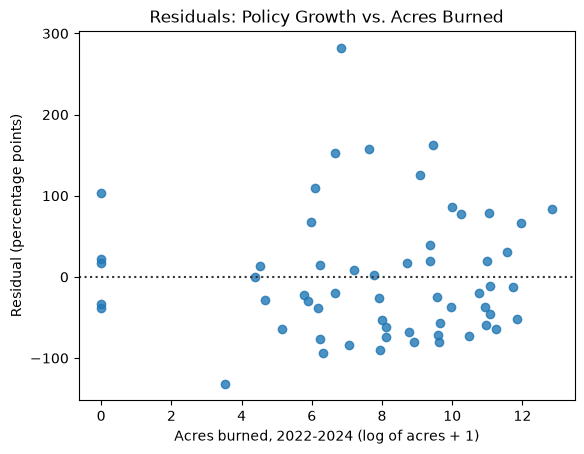

In [22]:
# 5.8 Residuals: distance of each county from the fitted line
sns.residplot(
    data=county_table,
    x='log_acres',
    y='policy_growth_pct',
).set(
    title  = 'Residuals: Policy Growth vs. Acres Burned',
    xlabel = 'Acres burned, 2022-2024 (log of acres + 1)',
    ylabel = 'Residual (percentage points)',
);


Policy growth fell by about 8.5 percentage points for each one-unit increase in log acres burned (p = 0.011, R² = 0.11), but without the five zero-acre counties the slope is no longer distinguishable from zero (section 7.4). Nigel found no straight-line link with raw acres (Pearson r = −0.085, p = 0.525) but a negative one by rank (Spearman rho = −0.312, p = 0.017); the histograms show why the scale matters: raw acres are bunched near zero with one county far above the rest, while the log scale (like ranks) spreads the counties out and sets the five zero-acre counties apart, all with growth above most counties that burned.


## 6. Both together

In [23]:
# 6.1 Fit growth explained by income and acres burned together
m_both = smf.ols("policy_growth_pct ~ income_10k + log_acres", data=county_table).fit()


In [24]:
# 6.2 Show the model results
m_both.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.115
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     3.584
Date:                Mon, 16 Nov 2026   Prob (F-statistic):             0.0344
Time:                        21:14:48   Log-Likelihood:                -334.71
No. Observations:                  58   AIC:                             675.4
Df Residuals:                      55   BIC:                             681.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    165.4982     55.892      2.961      0.005      53.488     277.508
income_10k     2.5733      4.593      0.560      0.578      -6.631      11.777
log_acres     -7.6821      3.509     -2.189      0.033     -14.714      -0.651
==============================================================================
Omnibus:                       15.884   Durbin-Watson:                   1.916
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               18.311
Skew:                           1.182   Prob(JB):                     0.000106
Kurtosis:                       4.411   Cond. No.                         62.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [25]:
# 6.3 Standardize income and log acres (mean 0, standard deviation 1)
county_table = (
    county_table
    .assign(
        income_z    = lambda df: (df['income_10k'] - df['income_10k'].mean()) / df['income_10k'].std(),
        log_acres_z = lambda df: (df['log_acres'] - df['log_acres'].mean()) / df['log_acres'].std(),
    )
)


In [26]:
# 6.4 Check: each new column has mean 0 and standard deviation 1
county_table[['income_z', 'log_acres_z']].agg(['mean', 'std'])


,income_z,log_acres_z
mean,1.531342e-17,-3.014830e-16
std,1.000000e+00,1.000000e+00


In [27]:
# 6.5 Refit with the standardized columns
m_both_z = smf.ols("policy_growth_pct ~ income_z + log_acres_z", data=county_table).fit()


In [28]:
# 6.6 Show the standardized results
m_both_z.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.115
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     3.584
Date:                Mon, 16 Nov 2026   Prob (F-statistic):             0.0344
Time:                        21:14:48   Log-Likelihood:                -334.71
No. Observations:                  58   AIC:                             675.4
Df Residuals:                      55   BIC:                             681.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     127.0110     10.467     12.134      0.000     106.034     147.988
income_z        6.4295     11.475      0.560      0.578     -16.567      29.426
log_acres_z   -25.1240     11.475     -2.189      0.033     -48.120      -2.128
==============================================================================
Omnibus:                       15.884   Durbin-Watson:                   1.916
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               18.311
Skew:                           1.182   Prob(JB):                     0.000106
Kurtosis:                       4.411   Cond. No.                         1.51
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

With both in one model, acres burned remained associated with lower policy growth (−7.7 per log acre, p = 0.033) while income did not (2.6 per $10k, p = 0.58); in standardized units the acres coefficient (−25.1) was about four times the income one (6.4). Without the five zero-acre counties neither was distinguishable from zero (section 7.4), so this model does not settle which of the two goes with growth, and together they account for little of it (R² = 0.115).


## 7. Checks

### 7.1 Without the four small-base counties

In [29]:
# 7.1 Drop the four small-base counties
county_no_small = county_table.query('small_base == False')
print(county_no_small.shape)


(54, 13)


In [30]:
# 7.2 Refit the income model without the four small-base counties
m_income_no_small = smf.ols("policy_growth_pct ~ income_10k", data=county_no_small).fit()


In [31]:
# 7.3 Show the results without the four small-base counties
m_income_no_small.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.039
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     2.083
Date:                Mon, 16 Nov 2026   Prob (F-statistic):              0.155
Time:                        21:14:48   Log-Likelihood:                -315.47
No. Observations:                  54   AIC:                             634.9
Df Residuals:                      52   BIC:                             638.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     71.9511     40.035      1.797      0.078      -8.384     152.287
income_10k     6.5843      4.562      1.443      0.155      -2.570      15.738
==============================================================================
Omnibus:                       12.055   Durbin-Watson:                   1.825
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               12.356
Skew:                           1.110   Prob(JB):                      0.00207
Kurtosis:                       3.753   Cond. No.                         30.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Without the four small-base counties the income slope was almost unchanged (6.6 per $10k, p = 0.155, n = 54), likely because their growth (71% to 155%) was not extreme. This check was only run on the income model.


### 7.4 Without the five zero-acre counties

In [32]:
# 7.4 Drop the five counties with no acres burned
county_no_zero = county_table.loc[~no_fire_mask]
print(county_no_zero.shape)


(53, 13)


In [33]:
# 7.5 Refit the acres-only model without the zero-acre counties
m_fire_no_zero = smf.ols("policy_growth_pct ~ log_acres", data=county_no_zero).fit()


In [34]:
# 7.6 Show the acres-only results without the zero-acre counties
m_fire_no_zero.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     1.639
Date:                Mon, 16 Nov 2026   Prob (F-statistic):              0.206
Time:                        21:14:48   Log-Likelihood:                -307.20
No. Observations:                  53   AIC:                             618.4
Df Residuals:                      51   BIC:                             622.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    172.5806     42.987      4.015      0.000      86.281     258.880
log_acres     -6.2346      4.870     -1.280      0.206     -16.013       3.543
==============================================================================
Omnibus:                       17.305   Durbin-Watson:                   1.925
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               21.080
Skew:                           1.273   Prob(JB):                     2.65e-05
Kurtosis:                       4.751   Cond. No.                         34.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [35]:
# 7.7 Refit the income-plus-acres model without the zero-acre counties
m_both_no_zero = smf.ols("policy_growth_pct ~ income_10k + log_acres", data=county_no_zero).fit()


In [36]:
# 7.8 Show the income-plus-acres results without the zero-acre counties
m_both_no_zero.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.038
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.9864
Date:                Mon, 16 Nov 2026   Prob (F-statistic):              0.380
Time:                        21:14:48   Log-Likelihood:                -307.01
No. Observations:                  53   AIC:                             620.0
Df Residuals:                      50   BIC:                             625.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    138.2775     72.017      1.920      0.061      -6.373     282.928
income_10k     2.9517      4.954      0.596      0.554      -6.999      12.903
log_acres     -5.0303      5.302     -0.949      0.347     -15.680       5.619
==============================================================================
Omnibus:                       16.919   Durbin-Watson:                   1.864
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               20.060
Skew:                           1.283   Prob(JB):                     4.41e-05
Kurtosis:                       4.581   Cond. No.                         77.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Without the five zero-acre counties (n = 53), the acres slope shrank from −8.5 to −6.2 and was no longer distinguishable from zero (p = 0.21, R² = 0.03, 95% interval −16.0 to 3.5). With both in the model, neither acres (−5.0, p = 0.35) nor income (3.0 per $10k, p = 0.55) was, and the model as a whole was not either (p = 0.38). So the acres result in sections 5 and 6 rests on five counties that had no fire in 2022–2024 and comparatively high growth; the interval still allows a weaker negative link among counties that burned.


**Limitation.** In every model the residuals are skewed to the right (skew 1.1 to 1.3, Jarque-Bera p < 0.01 in every summary), and the residual plots show a few counties with growth far above the line, so the p-values are approximate and a handful of high-growth counties carry a lot of weight.
